# EM Data 
This code will recreate figure panels as well as plot individual dendrites and determine summary values of key variables
>  mean diam <br>
>  length <br>

In [1]:
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd 
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

###can also use dir() to check what is in function and that new params have been loaded

import os
import glob


#desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
plot_path="../output/plots"
mypath = plot_path

import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc
import os

## Load dendritic diameter data
Set location of repo data (root folder) sets the paths for each expanded dendrite analysed

In [2]:
# Define the root directory and check if it exists
root = '../repo_data/EM'
if not os.path.exists(root):
    raise FileNotFoundError(f"Root folder '{root}' not found.")

# Helper function to add branches
def add_branch(data, branch_name, folder, filename, ex_factor=1, res=0.01):
    data[branch_name] = {
        'path': os.path.join(folder, filename),
        'ex_factor': ex_factor,
        'res': res
    }

# Initialize the EM data dictionary
EMdata = {}

# Set up folders and files
folder1 = os.path.join(root, 'DD0075_E5', 'tables')
folder2 = os.path.join(root, '1922_DistalMolLayer', 'tables')

# Add branches with helper function
add_branch(EMdata, 'branch1', folder1, 'D1_binary - Local Diameter.csv')
add_branch(EMdata, 'branch2', folder1, 'D2_binary - Local Diameter.csv')
add_branch(EMdata, 'branch4', folder1, 'D4_binary - Local Diameter.csv')
add_branch(EMdata, 'branch5', folder1, 'D5_binary - Local Diameter.csv')

add_branch(EMdata, 'branch3', folder1, '03 - Local Diameter.csv')
add_branch(EMdata, 'branch6', folder1, '06 - Local Diameter.csv')
add_branch(EMdata, 'branch7', folder1, '07 - Local Diameter.csv')
add_branch(EMdata, 'branch8', folder1, '08 - Local Diameter.csv')
add_branch(EMdata, 'branch9', folder1, '09 - Local Diameter.csv')

add_branch(EMdata, 'branch12', folder2, 'object02 - Local Diameter.csv')
add_branch(EMdata, 'branch13', folder2, 'object03 - Local Diameter.csv')
add_branch(EMdata, 'branch14', folder2, 'object04 - Local Diameter.csv')
add_branch(EMdata, 'branch17', folder2, 'object07 - Local Diameter.csv')

# Uncomment if needed after verification with Michael
# add_branch(EMdata, 'branch19', folder2, 'object092 - Local Diameter.csv')

add_branch(EMdata, 'branch20', folder2, 'object10 - Local Diameter.csv')
add_branch(EMdata, 'branch21', folder2, 'object11 - Local Diameter.csv')
add_branch(EMdata, 'branch22', folder2, 'object12 - Local Diameter.csv')
add_branch(EMdata, 'branch25', folder2, 'object15 - Local Diameter.csv')

# Optionally, print or log EMdata to verify paths and parameters
print(EMdata)

{'branch1': {'path': '../repo_data/EM/DD0075_E5/tables/D1_binary - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch2': {'path': '../repo_data/EM/DD0075_E5/tables/D2_binary - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch4': {'path': '../repo_data/EM/DD0075_E5/tables/D4_binary - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch5': {'path': '../repo_data/EM/DD0075_E5/tables/D5_binary - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch3': {'path': '../repo_data/EM/DD0075_E5/tables/03 - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch6': {'path': '../repo_data/EM/DD0075_E5/tables/06 - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch7': {'path': '../repo_data/EM/DD0075_E5/tables/07 - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch8': {'path': '../repo_data/EM/DD0075_E5/tables/08 - Local Diameter.csv', 'ex_factor': 1, 'res': 0.01}, 'branch9': {'path': '../repo_data/EM/DD0075_E5/tables/09 - Local Diameter.csv', 'ex_factor'

Load and analyse each dendritic section in EM dataset

In [3]:
dataSet=EMdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'], p=100, pdiff=1)

100%|████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:00<00:00, 182.72it/s]


Manually adjust DSC 
> add DSCs missing as diam increses slighlty in the middle <br>
> remove false postives

In [4]:
### add manual to the data dictionary 
# ##add manual branch5 goes below x2 threshold but sligth increase excludes it from algorythm eventhough still DSC in my opinion  
branch=EMdata['branch4']
DSC=branch['data'][120:275].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 

branch=EMdata['branch5']
DSC=branch['data'][360:700].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC)  

branch=EMdata['branch14']
DSC=branch['data'][364:450].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC)  


##maybe other DSCs in branch 17 object7 but difficult to confirm without proper registration.
del EMdata['branch17']['DSCs'][1]


In [5]:
update_DSCs(EMdata['branch4'])
update_DSCs(EMdata['branch5'])

# update_DSCs(EMdata['branch8']) # end of dendrite
update_DSCs(EMdata['branch14'])

update_DSCs(EMdata['branch17'])
# update_DSCs(EMdata['branch20'])

### Create figure panels for Fig1 
Fig1g DSC mean diameter<br>
Fig1h DSC lenght

length mean = 1.1582555555555554 +- sem 0.332927097922149 count 9


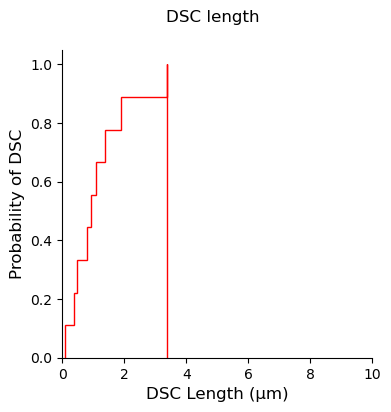

In [6]:
#select property to plot [mean, lenght]
parameter='length'

df= summary_dsc(EMdata, parameter)

n_bins=200
fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle('DSC '+parameter)

df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='red', density=True, histtype='step', cumulative=True)
ax.set_xlim([0,10])


# Add x and y labels
ax.set_xlabel("DSC Length (μm)", fontsize=12)
ax.set_ylabel("Probability of DSC", fontsize=12)

fig.savefig(mypath+'/EM_DSC_'+parameter+'_Cumulative.svg', bbox_inches = 'tight')
print(f"{parameter} mean = {df.mean()} +- sem {df.sem()} count {df.count()}")


### Select dendrite and branch to analyse
Example dendrite shown in Fig. 1f

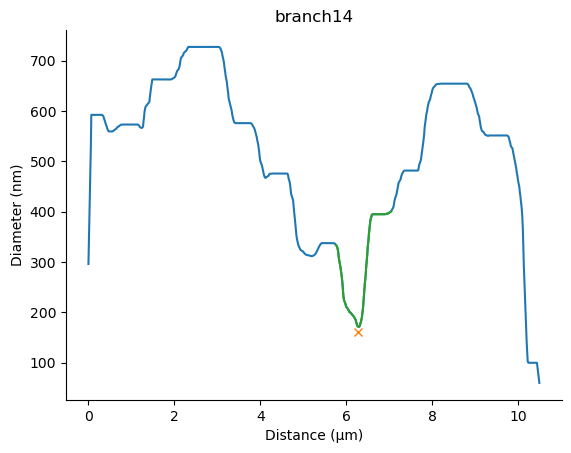

In [7]:
from plots import plot_dsc
dend_name= 'branch14'  
df=EMdata[dend_name]['data']
df=EMdata[dend_name]['DSC_properties']
fig, ax = plot_dsc(EMdata[dend_name],dend_name, corr=1)  

Get the dataframe itself and summary of the data

In [8]:
df= summary_dsc(EMdata, parameter)

In [9]:
minX=np.argmin(DSC.smth)

start = np.argmin(DSC.deriv2[0:minX+DSC.index.start+-3]) #-3 DSC.index[0])
end = np.argmax(DSC.deriv2[minX+3:]) + minX+3 #+3 DSC.index[0])